# MERSCOPE & CosMx: Platform Generalization

`01_core_workflow.ipynb` covered the standard Xenium pipeline: load, inspect, QC/filter, normalize, visualize, cluster, annotate, save. Xenium is one of three segmented-cell spatial platforms astrolabe supports — Vizgen MERSCOPE and NanoString CosMx are the other two.

This notebook is deliberately brief. It assumes familiarity with `01_core_workflow.ipynb` and focuses on what is platform-specific versus what is shared: one MERSCOPE sample and one CosMx sample are loaded, filtered through their platform-specific recipes, and confirmed to run the same shared downstream pipeline.

Both datasets are real public data (MERSCOPE ~126 MB, CosMx ~155 MB); the first run downloads and caches under `.astrolabe_cache/datasets/`.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab

## 1. Load MERSCOPE

`ab.datasets.merscope()` downloads a Vizgen MERSCOPE assembloid sample (Zenodo 13835782, region 0) and internally calls `ab.io.read_merscope(..., load_boundaries=False)` — same shape of call as `read_xenium`, different vendor file format (`cell_by_gene.csv` + `cell_metadata.csv` instead of a 10x `outs/` folder), returning the same kind of object: a `MuData` with a single modality (here `'merscope'`) and `uns['default_modality']` set automatically.

`load_boundaries=False` is the one choice worth flagging immediately: it means this `MuData` will have **no** `obsm['cell_boundaries']` / `obsm['nucleus_boundaries']`. Two things that depend on those polygons won't have anything to work with — `pl.boundaries()` (nothing to draw) and the `seg` module (no polygons to resegment or evaluate against). Everything that only needs centroids (`obsm['spatial']`) — `pl.points()`, QC, normalization, clustering, spatial stats — is unaffected.

In [2]:
mdata_m = ab.datasets.merscope()
ab.summary(mdata_m)

INFO:astrolabe.io._merscope:Reading MERSCOPE run 'merscope' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\merscope


INFO:astrolabe.io._merscope:Flagged 50 / 550 features as control probes (Blank-*)


INFO:astrolabe.io._merscope:Loaded 90981 cells × 550 genes (50 control probes)


MuData Summary
==================================================
Modalities:
  merscope (default): 90,981 cells × 550 vars, 50 control probes
Extent: x=[6191, 11822] µm  y=[5985, 11020] µm
Libraries (1):
  merscope: C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\merscope  (0 image(s))
Stats: mean area=153.2 µm²
Obs columns:
  QC: cell_area
  Other: volume, min_x, min_y, max_x, max_y, fov

`ab.pp.calculate_qc_metrics` is the platform-agnostic QC function (the same one used in notebook 01): it depends only on `X` and `var_names` existing, not on which platform produced the data. The resulting `total_counts` can be used directly to color `pl.points()`, the first proof that the "no boundaries" choice above didn't break anything spatial: it only ever reads `obsm['spatial']` centroids.

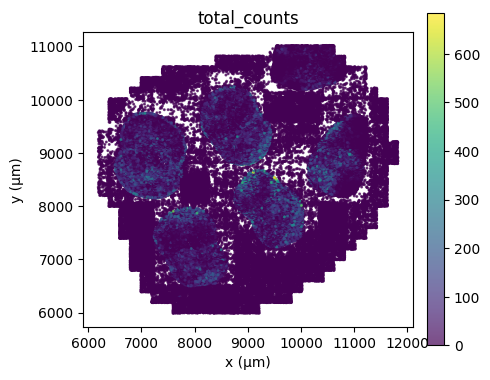

In [3]:
ab.pp.calculate_qc_metrics(mdata_m)
ab.pl.points(mdata_m, color='total_counts').show()

In [4]:
# Gene-level QC: per-gene detection rate vs. mean expression.
# Points above the main trend line are unusually well-detected (potentially good markers);
# points far below are low-sensitivity probes or dropout-heavy genes.
# control_key matches the is_control_probe column written by read_merscope.
ab.pl.gene_detection_scatter(mdata_m, control_key='is_control_probe').show()

In the gene detection scatter, genes on the main diagonal trend (mean expression tracks detection rate) are behaving as expected — higher-expressing genes are detected in more cells. Genes sitting clearly **above** the trend are detected in a higher fraction of cells than their mean expression predicts: these are robust, high-specificity markers where low expression is rarely confused with absence. The Blank-* control probes (highlighted) should cluster near the origin at very low mean and very low detection rate; a control probe with elevated detection indicates barcode collision or optical noise, not biology, and warrants further investigation.

## 2. QC & filter: `pipeline.filter_merscope`

The Xenium recipe does not apply here — `calculate_xenium_qc_metrics` is specific to Xenium's probe-type breakdown (unassigned codewords, deprecated codewords, genomic controls). MERSCOPE's equivalent is simpler: blank barcodes named `Blank-*`, already flagged in `var['is_control_probe']` at load time.

`pipeline.filter_merscope` calls `pp.flag_controls` against that existing flag, then defers to the same shared `filter_cells` steps (`calculate_qc_metrics`, `pp.filter_cells`, `pp.filter_genes`, spatial isolation) that `filter_xenium` also uses. The default `max_pct_control=5.0` is tighter than `filter_xenium`'s `10.0`, reflecting fewer expected blank-barcode reads on MERSCOPE panels.

In [5]:
n_before = mdata_m['merscope'].n_obs
ab.pipeline.filter_merscope(mdata_m)
print(f"{n_before} -> {mdata_m['merscope'].n_obs} cells")

INFO:astrolabe.pipeline:filter_merscope: 90981 cells × 550 genes


INFO:astrolabe.pipeline:  flag_controls (var_col='is_control_probe')


INFO:astrolabe.pp._qc:flag_controls: 50 / 550 features flagged as controls; obs['pct_counts_control'] computed (median 0.00%, max 0.00%)


INFO:astrolabe.pipeline:filter_cells: 90981 cells × 550 genes


INFO:astrolabe.pp._qc:filter_cells: removing 58525 / 90981 cells


...

INFO:astrolabe.pipeline:filter_cells: done — 32384 cells × 500 genes


INFO:astrolabe.pp._qc:filter_genes: removing 0 / 500 features


INFO:astrolabe.pipeline:  [remove_controls] 500 → 500 genes  (removed 0, 0.0%)


INFO:astrolabe.pipeline:filter_merscope: done — 32384 cells × 500 genes


90981 -> 32384 cells


The MERSCOPE assembloid sample (brain organoid, Zenodo 13835782) removes 64.3% of cells (58,525 / 90,981), far more than CosMx's 2.4% filtered later in this notebook. This reflects the dataset, not the platform: organoid cultures frequently produce small, fragmented, or incompletely-grown cells that pass segmentation but generate near-zero transcript counts, which `filter_cells`'s `min_counts` threshold removes. A similarly large drop on other MERSCOPE data is worth checking against the `total_counts` distribution first before adjusting thresholds: a bimodal distribution with a peak near zero confirms the removed cells are empty masks, not biological cells.

From here the pipeline is platform-agnostic: `pp.normalize_total`/`pp.log1p` work on any `AnnData`/`MuData` with an `X` matrix.

In [6]:
ab.pp.normalize_total(mdata_m)
ab.pp.log1p(mdata_m)
print("MERSCOPE: normalize_total + log1p ran cleanly")

MERSCOPE: normalize_total + log1p ran cleanly


## 3. Load CosMx

A third vendor, the same loading pattern: `ab.datasets.cosmx()` downloads the NanoString CosMx Lung12 public sample and calls `ab.io.read_cosmx(..., load_boundaries=False)`. CosMx's own file format is yet another shape (`*_exprMat_file.csv` + `*_metadata_file.csv`, with compound `{fov}_{cell_ID}` cell IDs and pixel-space coordinates converted to microns internally), but the result is, again, just a `MuData` with `obsm['spatial']` in microns and `uns['default_modality'] = 'cosmx'`. `load_boundaries=False` has the same consequence as before: no `obsm['cell_boundaries']`/`obsm['nucleus_boundaries']`.

In [7]:
mdata_c = ab.datasets.cosmx()
ab.summary(mdata_c)

INFO:astrolabe.io._cosmx:Reading CosMx run 'cosmx' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\cosmx


INFO:astrolabe.io._cosmx:Dropping 28 background pseudo-cell row(s) (cell_ID == 0)


INFO:astrolabe.io._cosmx:Flagged 20 / 980 features as control probes (NegPrb/Negative/SystemControl/FalseCode)


INFO:astrolabe.io._cosmx:Loaded 73997 cells × 980 genes (20 control probes)


MuData Summary
==================================================
Modalities:
  cosmx (default): 73,997 cells × 980 vars, 20 control probes
Extent: x=[-598, 2033] µm  y=[-19272, -16201] µm
Libraries (1):
  cosmx: C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\cosmx  (0 image(s))
Stats: mean area=55.3 µm²
Obs columns:
  QC: cell_area
  Other: fov, Width, Height, cell_ID

The same QC step and spatial scatter plot run unchanged, using only `obsm['spatial']` centroids — no boundary polygons required.

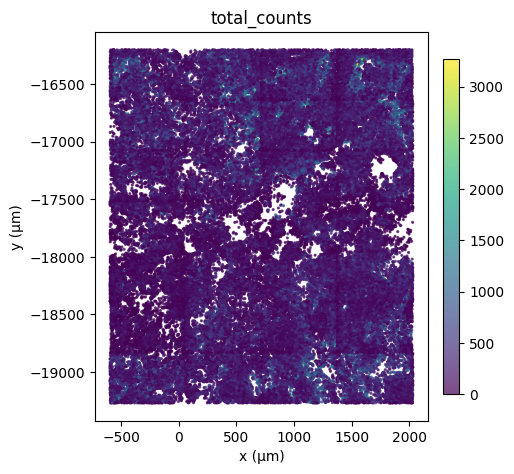

In [8]:
ab.pp.calculate_qc_metrics(mdata_c)
ab.pl.points(mdata_c, color='total_counts').show()

In [9]:
# Same gene-level QC scatter for CosMx.
# NegPrb*/SystemControl*/FalseCode* probes flagged by read_cosmx appear in a
# distinct cluster (highlighted in the plot) well off the main detection-vs-expression trend.
ab.pl.gene_detection_scatter(mdata_c, control_key='is_control_probe').show()

The CosMx scatter has the same interpretation: on-trend genes are well-behaved, above-trend genes are high-specificity markers, and control probes (`NegPrb*`, `SystemControl*`, `FalseCode*`) should cluster near the origin. CosMx panels are typically larger (980 genes here vs. MERSCOPE's 550) and use a different optical encoding, which shifts the absolute noise floor. Compare gene positions *within* each platform's own scatter rather than between platforms — a gene that sits above trend on one platform and on-trend on another may reflect panel design differences rather than a probe failure.

`pipeline.filter_cosmx` has the same shape as `filter_merscope`: flag controls from `var['is_control_probe']`, then defer to shared `filter_cells`, but the control-probe naming convention is CosMx-specific: `read_cosmx` flags `NegPrb*`, `SystemControl*`, and `FalseCode*` probes (vs. MERSCOPE's `Blank-*`). `filter_cosmx`'s default `max_pct_control=5.0` matches `filter_merscope`'s. `filter_xenium` is the only recipe with an extra platform-specific QC step; `filter_merscope` and `filter_cosmx` differ only in which control-probe names were flagged at read time.

In [10]:
n_before = mdata_c['cosmx'].n_obs
ab.pipeline.filter_cosmx(mdata_c)
print(f"{n_before} -> {mdata_c['cosmx'].n_obs} cells")

INFO:astrolabe.pipeline:filter_cosmx: 73997 cells × 980 genes


INFO:astrolabe.pipeline:  flag_controls (var_col='is_control_probe')


INFO:astrolabe.pp._qc:flag_controls: 20 / 980 features flagged as controls; obs['pct_counts_control'] computed (median 0.46%, max 100.00%)


INFO:astrolabe.pipeline:filter_cells: 73997 cells × 980 genes


INFO:astrolabe.pp._qc:filter_cells: removing 1739 / 73997 cells


...

INFO:astrolabe.pipeline:filter_cells: done — 72243 cells × 980 genes


INFO:astrolabe.pp._qc:filter_genes: removing 20 / 980 features


INFO:astrolabe.pipeline:  [remove_controls] 980 → 960 genes  (removed 20, 2.0%)


INFO:astrolabe.pipeline:filter_cosmx: done — 72243 cells × 960 genes


73997 -> 72243 cells


CosMx removes only 2.4% of cells (1,739 / 73,997), consistent with the fresh-frozen clinical Lung12 specimen having dense, well-captured cells rather than the fragmented segmentation masks seen in the MERSCOPE organoid sample above. As a rule of thumb, filter rates below 10% are expected for dense tissue (lung parenchyma, tumor core); rates above 30% signal either a sparse tissue type or a segmentation algorithm over-generating empty masks. Inspect `obs['total_counts']` and `obs['cell_area']` before adjusting thresholds: a sharp low-count spike at 0–5 transcripts confirms empty masks, while a broad bimodal distribution suggests genuinely low-quality biological cells requiring a different QC approach.

In [11]:
ab.pp.normalize_total(mdata_c)
ab.pp.log1p(mdata_c)
print("CosMx: normalize_total + log1p ran cleanly")

CosMx: normalize_total + log1p ran cleanly


## 4. Shared vs. platform-specific behavior

**Identical across Xenium, MERSCOPE, and CosMx:**

- `@with_adata` resolution — every function above was called with the whole `MuData`, never `mdata['merscope']`/`mdata['cosmx']` directly, and it resolved correctly via `uns['default_modality']` every time.
- `obsm['spatial']` is always `(n_cells, 2)` float32 **microns** — `pl.points()`, `pp.calculate_qc_metrics`, and every spatial function ran unmodified on all three platforms.
- `pp.normalize_total`, `pp.log1p`, `tl.spatial_neighbors`, `tl.cluster`, `tl.pca`, `tl.umap`, `tl.rank_genes_groups` — all platform-agnostic; nothing in this notebook needed a CosMx- or MERSCOPE-specific normalization or clustering call.
- `pipeline.filter_cells` — the shared core that every `filter_<platform>` recipe defers to (QC metrics → cell filter → gene filter → spatial isolation filter).

**Platform-specific:**

- **Control-probe handling.** Xenium gets a dedicated `calculate_xenium_qc_metrics` step (probe-type breakdown: unassigned/deprecated codewords, genomic controls, …) before the shared steps. MERSCOPE and CosMx both just flag an existing `var['is_control_probe']` column (`Blank-*` vs. `NegPrb*`/`SystemControl*`/`FalseCode*`) via `pp.flag_controls` — no probe-type breakdown, because their panels don't have one.
- **Boundary availability.** All three datasets here were loaded with `load_boundaries=False`, so none of the three `MuData` objects have `obsm['cell_boundaries']`/`obsm['nucleus_boundaries']` — that's a loader argument, not a platform limitation. Note that `pl.boundaries()` and `seg.*` require boundary polygons regardless of platform.
- **Filter recipe defaults.** `filter_xenium`'s `max_pct_control` defaults to `10.0`; `filter_merscope` and `filter_cosmx` both default to a tighter `5.0`. `filter_xenium` is the only recipe with an extra platform-specific QC call ahead of the shared `filter_cells` steps — `filter_merscope`/`filter_cosmx` differ from each other only in *which* control-probe prefixes were flagged at read time, not in the recipe shape.

The pattern generalizes to any vendor. For a fourth segmented-cell platform without a named reader in astrolabe, `pipeline.filter_cells` plus a custom `var['is_control_probe']` flag (or skipping `max_pct_control` entirely) is the pattern to copy.